In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# (4 балла) Задача 1. Сравнение двух смещённых оценок

Пусть $X_1,\ldots,X_4$ независимы и одинаково распределены, причём

$$
\mathbb{E}[X_i]=\theta,
\qquad
\operatorname{Var}(X_i)=1.
$$

Рассмотрим две оценки параметра $\theta$:

$$
\widehat{\theta}_1=\overline{X}-1,
\qquad
\widehat{\theta}_2=0.5\overline{X}+1.
$$

1. Найди смещение и дисперсию оценки $\widehat{\theta}_1$.

2. Найди смещение и дисперсию оценки $\widehat{\theta}_2$.

3. Вычисли $\operatorname{MSE}_{\theta}$ обеих оценок и определи значения $\theta$, при которых $\widehat{\theta}_2$ имеет меньшую MSE.

4. Построй графики $\operatorname{MSE}_{\theta}(\widehat{\theta}_1)$ и $\operatorname{MSE}_{\theta}(\widehat{\theta}_2)$ в зависимости от $\theta$. Отметь область, в которой вторая оценка имеет меньшую MSE.

$$
\operatorname{Bias}_{\theta}(\widehat\theta_1)
=\mathbb E_{\theta}[\widehat\theta_1]-\theta = 0.25 \sum_{n=1}^4\theta - 1 - \theta = -1.
$$

$$
\mathbb{V}_{\theta}(\widehat\theta_1)
=\mathbb V_{\theta}[\overline X-1] = 0.25^2 \sum_{n=1}^4\mathbb V_{\theta}(X_n) = 0.25^2 \cdot 4 = 1/4.
$$

$$
\operatorname{Bias}_{\theta}(\widehat\theta_2)
=\mathbb E_{\theta}[\widehat\theta_2]-\theta = 0.5 \cdot 0.25 \sum_{n=1}^4\theta + 1 - \theta = -0.5\theta + 1.
$$

$$
\mathbb{V}_{\theta}(\widehat\theta_2)
=\mathbb V_{\theta}[0.5\overline X+1] = 0.5^2 \cdot 0.25^2 \sum_{n=1}^4\mathbb V_{\theta}(X_n) = 0.5^2 \cdot 1/4 = 1/16.
$$

$$
\operatorname{MSE}_{\theta}(\widehat\theta_1)
=\mathbb V_{\theta}(\widehat\theta_1)+\operatorname{Bias}_{\theta}(\widehat\theta_1)^2 = 1/4 + (-1)^2 = 5/4.
$$

$$
\operatorname{MSE}_{\theta}(\widehat\theta_2)
=\mathbb V_{\theta}(\widehat\theta_2)+\operatorname{Bias}_{\theta}(\widehat\theta_2)^2 = 1/16 + (-0.5\theta+1)^2 = 1/4 * \theta^2-\theta+17/16.
$$


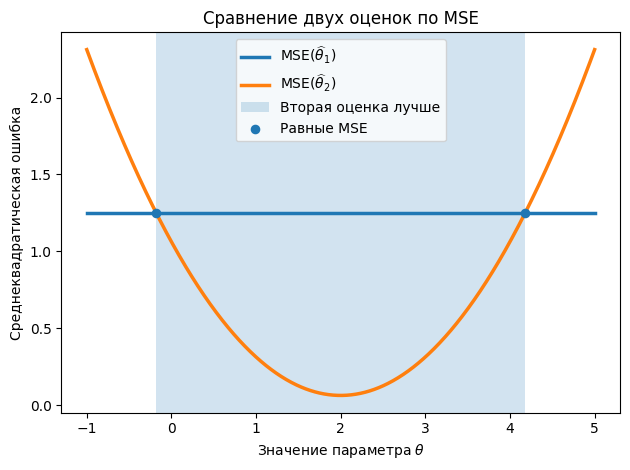

In [2]:
theta_grid = np.linspace(-1, 5, 1001)

mse_first = np.full_like(theta_grid, 1.25)
mse_second = 1/4 * theta_grid**2 - theta_grid + 17/16

lower_bound = 2 - np.sqrt(19)/2
upper_bound = 2 + np.sqrt(19)/2 

plt.plot(theta_grid, mse_first, linewidth=2.5, label=r"$\operatorname{MSE}(\widehat{\theta}_1)$")
plt.plot(theta_grid, mse_second, linewidth=2.5, label=r"$\operatorname{MSE}(\widehat{\theta}_2)$")
plt.axvspan(lower_bound, upper_bound, alpha=0.2, label="Вторая оценка лучше")

plt.scatter(
    [lower_bound, upper_bound],
    [1.25, 1.25],
    s=35,
    zorder=3,
    label="Равные MSE"
)

plt.xlabel(r"Значение параметра $\theta$")
plt.ylabel("Среднеквадратическая ошибка")
plt.title("Сравнение двух оценок по MSE")
plt.legend()
plt.tight_layout()
plt.show()

# (6 баллов) Задача 2. Конверсия и информация Фишера

Пусть для каждого пользователя

$$
X_i=\begin{cases}
1, & \text{если пользователь совершил покупку},\\
0, & \text{если не совершил}.
\end{cases}
$$

Предположим,

$$
X_1,\ldots,X_n\overset{\mathrm{iid}}{\sim}\operatorname{Bern}(p),
$$

где $p$ — неизвестная конверсия.

Для одного наблюдения

$$
\mathbb{P}_p(X=x)=p^x(1-p)^{1-x},\qquad x\in\{0,1\}.
$$

Нужно:

1. Найти score $U_p(X)$.
2. Привести score к виду с $X-p$ в числителе.
3. Найти $I_1(p)$ и $I_n(p)$.
4. Выписать границу Рао–Крамера для несмещённой оценки $p$.
5. Проверить эффективность выборочной конверсии $\widehat p=\overline X$.
6. Найти информацию Фишера, границу Рао–Крамера и стандартную ошибку $\widehat p$ при $p=0.2$, $n=100$.

Мы хотим оценить вероятность того, что пользователь совершил покупку.

### Score
$$
U_p(X) = \frac{d}{dp}(log(P_p(x)));
$$
$$
log(P_p(x)) = log(p^x) + log(1-p)^{1-x} = x * log(p) + (1-x) * log(1-p);
$$
$$
\boxed{U_p(x) = x * \frac{1}{p} - (1 - x) * \frac{1}{1-p} = \frac{x-p}{p(1-p)}}
$$

### Информация Фишера
$$
I_1(p) = \mathbf E[U_p^2(x)] = Var(U_p(x)) = \frac{Var(x-p)}{p^2(1-p)^2} = \frac{p(1-p)}{p^2(1-p)^2} = \frac{1}{p(1-p)}
$$
$$
\boxed{I_n(p) = \frac{n}{p(1-p)}}
$$

### Граница Рао-Крамера

$$
\boxed{\frac{1}{I_n(P)} = \frac{p(1-p)}{n}}
$$

### Проверка Эффективности выборочной конверсии $\widehat p=\overline X$.

$$
Var(\overline X) >= \frac{p(1-p)}{n}
$$

$$
\boxed{Var(\overline X) = \frac{1}{n^2} * n * Var(X) = \frac{p(1-p)}{n} \text{ - эффективна}.}
$$ 


### Информацию Фишера, границу Рао–Крамера и стандартную ошибку $\widehat p$ при $p=0.2$, $n=100$.

In [3]:
import numpy as np

p, n = 0.2, 100

I_1 = 1 / (p * (1 - p))
I_n = n * I_1

bound = 1 / I_n

se = np.sqrt(bound)

print(f"Информация Фишера (1 наблюдение):  I_1 = {I_1:.4f}")
print(f"Информация Фишера (n = {n}):       I_n = {I_n:.2f}")
print(f"Граница Рао-Крамера:               Var(p_hat) >= {bound:.6f}")
print(f"Стандартная ошибка:                SE = {se:.4f}")

Информация Фишера (1 наблюдение):  I_1 = 6.2500
Информация Фишера (n = 100):       I_n = 625.00
Граница Рао-Крамера:               Var(p_hat) >= 0.001600
Стандартная ошибка:                SE = 0.0400


# Бонусная задача. Математическое ожидание длины отрезка

Вершина $C$ прямого угла равнобедренного прямоугольного треугольника соединяется отрезком прямой с произвольной точкой $M$ основания.

Длина основания равна $3$ см. Найти математическое ожидание длины отрезка.

1. Опустим высоту $CH$ на основание. Она же медиана и равна 1/2 основания:
   $$
   CH=\frac32\text{ см}.
   $$

2. Пусть $x=HM$ — расстояние от середины основания до точки $M$. Тогда $x\in[0;3/2]$.
   CM=\sqrt{\left(\frac32\right)^2+x^2}
   =\sqrt{\frac94+x^2}.
   $$

3. Расстояние $x=HM$ равномерно распределено на отрезке $[0;3/2]$. Его плотность постоянна и равна $p$. Поскольку полная вероятность равна единице:
   $$
   1=\int_0^{3/2}p\,dx=\frac32p,
   \qquad p=\frac23.
   $$

   Поэтому математическое ожидание:
   $$
   E(CM) =\int_0^{\frac32}(\frac94 + x^2)^{1/2}*\frac23dx = \frac23*\int_0^{\frac32}\sqrt{\frac94 + x^2}dx
   $$


*Вычисление интеграла подсмотрел в ChatGPT.*
*Вычисление интеграла подсмотрел в ChatGPT.*

Обозначим:
$$
I=\int_0^{3/2}\sqrt{\frac94+x^2}\,dx.
$$

Тригонометрическая замена:
$$
x=\frac32\tan t,\qquad
dx=\frac32\frac{dt}{\cos^2 t}.
$$

$$
\sqrt{\frac94+x^2}=\frac32\frac1{\cos t}.
$$

При $x=0$ имеем $t=0$, а при $x=\frac32$ — $t=\frac\pi4$. Поэтому:
$$
I=\frac94\int_0^{\pi/4}\frac{dt}{\cos^3 t}.
$$

Взятие по частям.

Итак:
$$
I=\frac98\left(\sqrt2+\ln(1+\sqrt2)\right).
$$

## Ответ

$$
\boxed{
E(CM)=\frac23\cdot\frac98
\left(\sqrt2+\ln(1+\sqrt2)\right)
=\frac34\left(\sqrt2+\ln(1+\sqrt2)\right)
\approx1{,}722\text{ см}
}
$$